In [ ]:
from google.colab import files

uploaded = files.upload()


Saving billing.csv to billing.csv
Saving connections.csv to connections.csv
Saving maintenance.csv to maintenance.csv
Saving meter.csv to meter.csv
Saving weather.csv to weather.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

meter = pd.read_csv("meter.csv")
connections = pd.read_csv("connections.csv")
billing = pd.read_csv("billing.csv")
weather = pd.read_csv("weather.csv")
maintenance = pd.read_csv("maintenance.csv")

print("All five datasets loaded successfully!")


All five datasets loaded successfully!


In [ ]:

# CELL 3: Dataset overview

datasets = {
    "Meter": meter,
    "Connections": connections,
    "Billing": billing,
    "Weather": weather,
    "Maintenance": maintenance
}

for name, df in datasets.items():
    print(f"\n{'=' * 45}")
    print(name)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Column names:", df.columns.tolist())
    display(df.head())



Meter
Rows: 21601
Columns: 3
Column names: ['date', 'connection_id', 'usage']


,date,connection_id,usage
0,2025-01-01,C0001,0.409
1,2025-01-02,C0001,0.384
2,2025-01-03,C0001,0.395
3,2025-01-04,C0001,0.567
4,2025-01-05,C0001,0.462



Connections
Rows: 120
Columns: 4
Column names: ['connection_id', 'type', 'locality', 'household_size_band']


,connection_id,type,locality,household_size_band
0,C0001,Residential,Hillview,3-4
1,C0002,Commercial,Central,NaN
2,C0003,Residential,Hillview,5+
3,C0004,Residential,Lakeside,3-4
4,C0005,Residential,Hillview,5+



Billing
Rows: 720
Columns: 4
Column names: ['connection_id', 'billing_cycle', 'billed_usage', 'charge']


,connection_id,billing_cycle,billed_usage,charge
0,C0001,2025-01-01,15.01,525.46
1,C0001,2025-02-01,17.41,609.28
2,C0001,2025-03-01,16.29,570.26
3,C0001,2025-04-01,14.84,519.33
4,C0001,2025-05-01,15.53,543.45



Weather
Rows: 180
Columns: 3
Column names: ['date', 'temperature', 'rain']


,date,temperature,rain
0,2025-01-01,21.7,14.6
1,2025-01-02,20.7,0.0
2,2025-01-03,29.6,0.0
3,2025-01-04,22.6,0.0
4,2025-01-05,26.5,21.9



Maintenance
Rows: 12
Columns: 3
Column names: ['connection_id', 'leak_report', 'repair_date']


,connection_id,leak_report,repair_date
0,C0048,Yes,2025-02-09
1,C0111,Yes,2025-02-18
2,C0021,Yes,2025-02-22
3,C0101,Yes,2025-03-07
4,C0104,Yes,2025-03-19


In [ ]:

# CELL 4: Missing values, duplicates and data types

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nStatistical summary:")
    display(df.describe(include="all").T)



--- Meter ---

Data types:
date              object
connection_id     object
usage            float64
dtype: object

Missing values:
date             0
connection_id    0
usage            1
dtype: int64

Duplicate rows: 1

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,21601,180,2025-01-01,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
connection_id,21601,120,C0001,181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
usage,21600.0,NaN,NaN,NaN,1.052649,1.136211,-0.25,0.41075,0.518,0.75625,6.214



--- Connections ---

Data types:
connection_id          object
type                   object
locality               object
household_size_band    object
dtype: object

Missing values:
connection_id          0
type                   0
locality               0
household_size_band    5
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq
connection_id,120,120,C0001,1
type,120,2,Residential,93
locality,120,6,Riverside,27
household_size_band,115,6,3-4,48



--- Billing ---

Data types:
connection_id     object
billing_cycle     object
billed_usage     float64
charge           float64
dtype: object

Missing values:
connection_id    0
billing_cycle    0
billed_usage     0
charge           0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
connection_id,720,120,C0001,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
billing_cycle,720,6,2025-01-01,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
billed_usage,720.0,NaN,NaN,NaN,31.579667,33.585772,5.53,12.5575,15.54,21.6425,142.84
charge,720.0,NaN,NaN,NaN,1513.365236,1956.899301,193.62,439.675,543.86,757.5975,7856.14



--- Weather ---

Data types:
date            object
temperature    float64
rain           float64
dtype: object

Missing values:
date           0
temperature    0
rain           0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,180,180,2025-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature,180.0,NaN,NaN,NaN,27.919444,3.237164,20.7,25.55,28.1,30.525,35.2
rain,180.0,NaN,NaN,NaN,2.186667,5.60496,0.0,0.0,0.0,0.825,38.5



--- Maintenance ---

Data types:
connection_id    object
leak_report      object
repair_date      object
dtype: object

Missing values:
connection_id    0
leak_report      0
repair_date      0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq
connection_id,12,12,C0048,1
leak_report,12,1,Yes,12
repair_date,12,12,2025-02-09,1


Missing usage values: 1
Negative usage values: 1
Duplicate meter rows: 1

Highest water usage readings:


,date,connection_id,usage
16157,2025-05-18,C0090,6.214
16161,2025-05-22,C0090,6.211
7428,2025-02-18,C0042,5.983
230,2025-02-20,C0002,5.922
7442,2025-03-04,C0042,5.875
228,2025-02-18,C0002,5.846
16154,2025-05-15,C0090,5.825
16153,2025-05-14,C0090,5.743
7439,2025-03-01,C0042,5.710
17617,2025-06-07,C0098,5.653


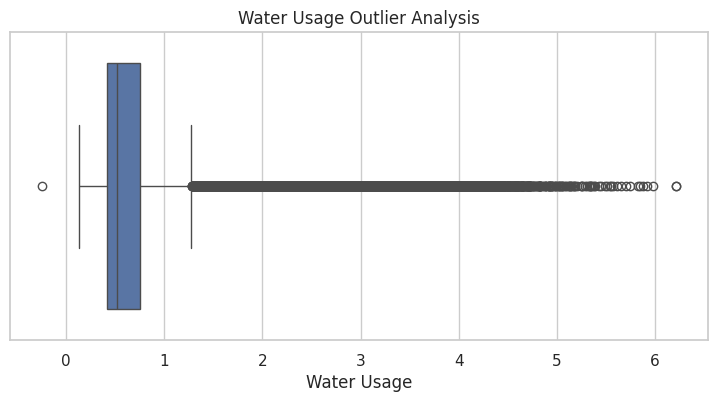

In [ ]:

# CELL 5: Investigate water usage quality

print("Missing usage values:", meter["usage"].isna().sum())
print("Negative usage values:", (meter["usage"] < 0).sum())
print("Duplicate meter rows:", meter.duplicated().sum())

print("\nHighest water usage readings:")
display(
    meter.sort_values("usage", ascending=False).head(10)
)

plt.figure(figsize=(9, 4))
sns.boxplot(x=meter["usage"])
plt.title("Water Usage Outlier Analysis")
plt.xlabel("Water Usage")
plt.show()


In [ ]:

# CELL 6: Clean all datasets

# Keep the original datasets unchanged
meter_clean = meter.copy()
connections_clean = connections.copy()
billing_clean = billing.copy()
weather_clean = weather.copy()
maintenance_clean = maintenance.copy()

# Convert date columns
meter_clean["date"] = pd.to_datetime(
    meter_clean["date"], errors="coerce"
)
weather_clean["date"] = pd.to_datetime(
    weather_clean["date"], errors="coerce"
)
billing_clean["billing_cycle"] = pd.to_datetime(
    billing_clean["billing_cycle"], errors="coerce"
)
maintenance_clean["repair_date"] = pd.to_datetime(
    maintenance_clean["repair_date"], errors="coerce"
)

# Remove duplicate records
meter_clean = meter_clean.drop_duplicates().copy()

# Replace invalid negative usage with missing value
meter_clean.loc[
    meter_clean["usage"] < 0, "usage"
] = np.nan

# Impute missing usage using each connection's median
meter_clean["usage"] = meter_clean.groupby(
    "connection_id"
)["usage"].transform(
    lambda s: s.fillna(s.median())
)

# Fallback if a connection has no valid usage values
meter_clean["usage"] = meter_clean["usage"].fillna(
    meter_clean["usage"].median()
)

# Handle missing household-size categories
connections_clean["household_size_band"] = (
    connections_clean["household_size_band"].fillna("Unknown")
)

# Remove records with invalid essential dates or identifiers
meter_clean = meter_clean.dropna(
    subset=["date", "connection_id", "usage"]
)

weather_clean = weather_clean.dropna(subset=["date"])
billing_clean = billing_clean.dropna(
    subset=["connection_id", "billing_cycle"]
)
maintenance_clean = maintenance_clean.dropna(
    subset=["connection_id", "repair_date"]
)

print("Cleaning completed.")
print("Clean meter rows:", len(meter_clean))
print("Clean connection rows:", len(connections_clean))
print("Clean billing rows:", len(billing_clean))
print("Clean weather rows:", len(weather_clean))
print("Clean maintenance rows:", len(maintenance_clean))


Cleaning completed.
Clean meter rows: 21600
Clean connection rows: 120
Clean billing rows: 720
Clean weather rows: 180
Clean maintenance rows: 12


In [ ]:

# CELL 7: Validate cleaned data

print("Missing meter usage:", meter_clean["usage"].isna().sum())
print("Negative meter usage:", (meter_clean["usage"] < 0).sum())
print("Duplicate meter rows:", meter_clean.duplicated().sum())

print(
    "Missing household-size values:",
    connections_clean["household_size_band"].isna().sum()
)

display(meter_clean.describe())


Missing meter usage: 0
Negative meter usage: 0
Duplicate meter rows: 0
Missing household-size values: 0


,date,usage
count,21600,21600.000000
mean,2025-03-31 12:00:00,1.052688
min,2025-01-01 00:00:00,0.135000
25%,2025-02-14 18:00:00,0.411000
50%,2025-03-31 12:00:00,0.518000
75%,2025-05-15 06:00:00,0.756250
max,2025-06-29 00:00:00,6.214000
std,NaN,1.136181


In [ ]:

# CELL 8: Merge daily water usage data

analysis_df = meter_clean.merge(
    connections_clean,
    on="connection_id",
    how="left",
    validate="many_to_one"
)

analysis_df = analysis_df.merge(
    weather_clean,
    on="date",
    how="left",
    validate="many_to_one"
)

analysis_df = analysis_df.merge(
    maintenance_clean[
        ["connection_id", "leak_report", "repair_date"]
    ],
    on="connection_id",
    how="left",
    validate="many_to_one"
)

# Create time-related features
analysis_df["month"] = analysis_df["date"].dt.month
analysis_df["day_of_week"] = analysis_df["date"].dt.dayofweek

# Flag observations before and after documented repairs
analysis_df["repair_recorded"] = (
    analysis_df["repair_date"].notna().astype(int)
)

analysis_df["days_from_repair"] = (
    analysis_df["date"] - analysis_df["repair_date"]
).dt.days

analysis_df["repair_period"] = np.select(
    [
        analysis_df["days_from_repair"].between(-14, -1),
        analysis_df["days_from_repair"].between(0, 14)
    ],
    ["Before repair", "After repair"],
    default="Other"
)

print("Combined dataset shape:", analysis_df.shape)
display(analysis_df.head())


Combined dataset shape: (21600, 15)


,date,connection_id,usage,type,locality,household_size_band,temperature,rain,leak_report,repair_date,month,day_of_week,repair_recorded,days_from_repair,repair_period
0,2025-01-01,C0001,0.409,Residential,Hillview,3-4,21.7,14.6,NaN,NaT,1,2,0,NaN,Other
1,2025-01-02,C0001,0.384,Residential,Hillview,3-4,20.7,0.0,NaN,NaT,1,3,0,NaN,Other
2,2025-01-03,C0001,0.395,Residential,Hillview,3-4,29.6,0.0,NaN,NaT,1,4,0,NaN,Other
3,2025-01-04,C0001,0.567,Residential,Hillview,3-4,22.6,0.0,NaN,NaT,1,5,0,NaN,Other
4,2025-01-05,C0001,0.462,Residential,Hillview,3-4,26.5,21.9,NaN,NaT,1,6,0,NaN,Other


,mean,sum,count
locality,,,
Greenfield,1.317638,5217.848,3960
Lakeside,1.185158,2986.597,2520
Hillview,1.090124,2158.446,1980
Central,1.063881,4021.472,3780
Northside,0.936183,4212.824,4500
Riverside,0.852031,4140.872,4860


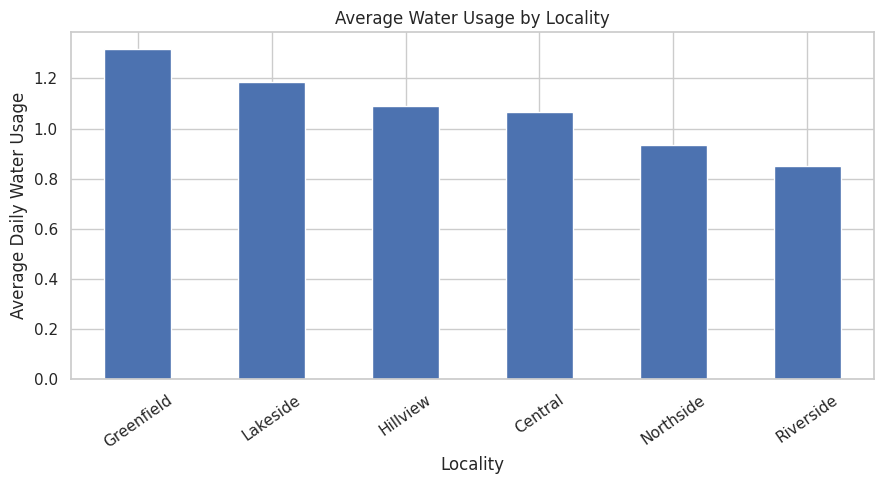

In [ ]:

# CELL 9: Water usage by locality

locality_usage = (
    analysis_df.groupby("locality")["usage"]
    .agg(["mean", "sum", "count"])
    .sort_values("mean", ascending=False)
)

display(locality_usage)

locality_usage["mean"].plot(
    kind="bar", figsize=(9, 5), title="Average Water Usage by Locality"
)

plt.ylabel("Average Daily Water Usage")
plt.xlabel("Locality")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


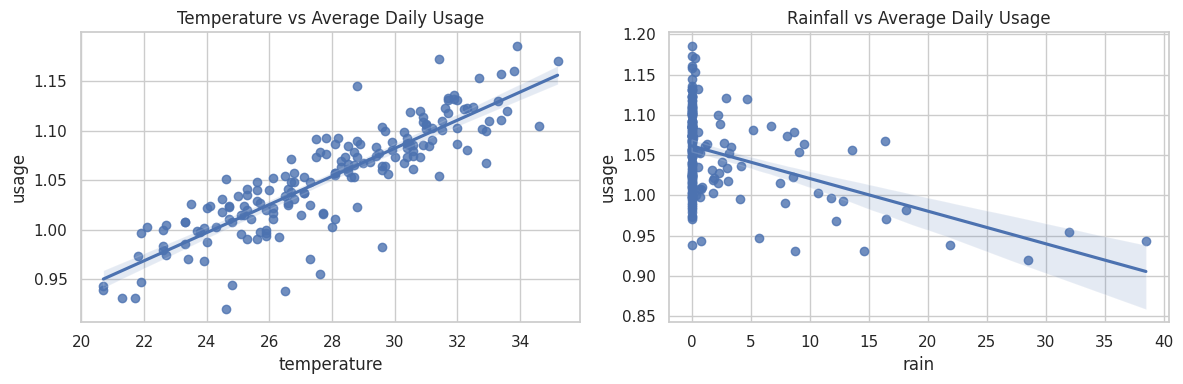

Weather correlations:


,usage,temperature,rain
usage,1.000000,0.863172,-0.426264
temperature,0.863172,1.000000,-0.093196
rain,-0.426264,-0.093196,1.000000


In [ ]:

# CELL 10: Weather versus water usage

weather_summary = (
    analysis_df.groupby("date", as_index=False)
    .agg(
        usage=("usage", "mean"),
        temperature=("temperature", "first"),
        rain=("rain", "first")
    )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.regplot(
    data=weather_summary,
    x="temperature", y="usage", ax=axes[0]
)
axes[0].set_title("Temperature vs Average Daily Usage")

sns.regplot(
    data=weather_summary,
    x="rain", y="usage", ax=axes[1]
)
axes[1].set_title("Rainfall vs Average Daily Usage")

plt.tight_layout()
plt.show()

print("Weather correlations:")
display(weather_summary[["usage", "temperature", "rain"]].corr())


In [ ]:

# CELL 11: Export results

meter_clean.to_csv("cleaned_meter.csv", index=False)
connections_clean.to_csv("cleaned_connections.csv", index=False)
billing_clean.to_csv("cleaned_billing.csv", index=False)
weather_clean.to_csv("cleaned_weather.csv", index=False)
maintenance_clean.to_csv("cleaned_maintenance.csv", index=False)
analysis_df.to_csv("water_usage_analysis.csv", index=False)

print("All cleaned datasets exported successfully.")


All cleaned datasets exported successfully.


In [ ]:

from google.colab import files

files.download("water_usage_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# CELL 11B: Detect unusual consumption

analysis_df = analysis_df.sort_values(
    ["connection_id", "date"]
).copy()

analysis_df["previous_14day_median"] = (
    analysis_df.groupby("connection_id")["usage"]
    .transform(
        lambda s: s.shift(1).rolling(
            14, min_periods=7
        ).median()
    )
)

analysis_df["usage_ratio"] = (
    analysis_df["usage"] /
    analysis_df["previous_14day_median"].replace(0, np.nan)
)

analysis_df["spike_flag"] = (
    (analysis_df["usage_ratio"] >= 1.8) &
    analysis_df["previous_14day_median"].notna()
)

spikes = analysis_df[analysis_df["spike_flag"]].copy()

print("Total spike readings:", len(spikes))
print("Connections with spikes:", spikes["connection_id"].nunique())

display(
    spikes[
        ["date", "connection_id", "locality", "type",
         "usage", "previous_14day_median", "usage_ratio"]
    ].sort_values("usage_ratio", ascending=False).head(15)
)


Total spike readings: 100
Connections with spikes: 17


,date,connection_id,locality,type,usage,previous_14day_median,usage_ratio
18605,2025-03-07,C0104,Riverside,Residential,1.625,0.4030,4.032258
19839,2025-02-09,C0111,Northside,Residential,1.602,0.4215,3.800712
18055,2025-02-25,C0101,Northside,Residential,1.680,0.4710,3.566879
8487,2025-01-28,C0048,Northside,Residential,1.322,0.3720,3.553763
9614,2025-03-16,C0054,Central,Residential,2.240,0.6345,3.530339
18053,2025-02-23,C0101,Northside,Residential,1.620,0.4590,3.529412
230,2025-02-20,C0002,Central,Commercial,5.922,1.7165,3.450044
228,2025-02-18,C0002,Central,Commercial,5.846,1.7165,3.405768
19836,2025-02-06,C0111,Northside,Residential,1.359,0.4020,3.380597
3640,2025-02-10,C0021,Greenfield,Residential,1.747,0.5230,3.340344


,mean,median,sum,count
type,,,,
Commercial,3.023,3.031,14690.591,4860
Residential,0.481,0.469,8047.468,16740


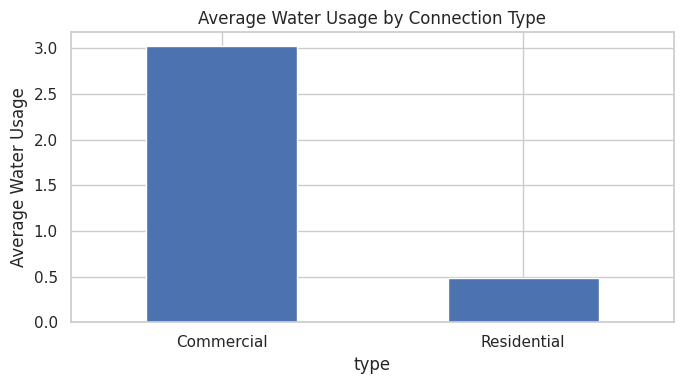

In [ ]:

# CELL 12: Connection-type comparison

type_summary = (
    analysis_df.groupby("type")["usage"]
    .agg(["mean", "median", "sum", "count"])
    .round(3)
)

display(type_summary)

type_summary["mean"].plot(
    kind="bar",
    figsize=(7, 4),
    title="Average Water Usage by Connection Type"
)

plt.ylabel("Average Water Usage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


period,After repair,Before repair,change_percent
connection_id,,,
C0021,0.535,1.315,-59.335
C0041,0.408,0.980,-58.429
C0048,0.380,0.868,-56.241
C0054,0.556,1.489,-62.657
C0059,0.566,1.277,-55.683
C0062,0.312,0.751,-58.425
C0067,0.264,0.692,-61.914
C0090,2.139,4.891,-56.267
C0092,0.412,1.253,-67.144


Connections with lower average usage after repair: 12


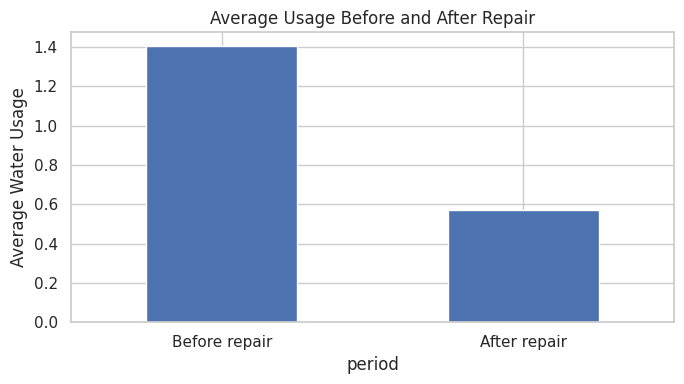

In [ ]:

# CELL 13: Compare usage before and after repair

repair_df = analysis_df[
    analysis_df["days_from_repair"].between(-14, 14)
].copy()

repair_df["period"] = np.where(
    repair_df["days_from_repair"] < 0,
    "Before repair",
    "After repair"
)

repair_summary = (
    repair_df.groupby(["connection_id", "period"])["usage"]
    .mean()
    .unstack()
)

repair_summary = repair_summary.dropna(
    subset=["Before repair", "After repair"]
)

repair_summary["change_percent"] = (
    (repair_summary["After repair"] -
     repair_summary["Before repair"]) /
    repair_summary["Before repair"].replace(0, np.nan)
) * 100

display(repair_summary.round(3))

print(
    "Connections with lower average usage after repair:",
    (repair_summary["change_percent"] < 0).sum()
)

repair_summary[["Before repair", "After repair"]].mean().plot(
    kind="bar",
    figsize=(7, 4),
    title="Average Usage Before and After Repair"
)

plt.ylabel("Average Water Usage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,mean,sum
month_name,,
Jan,1.021,3798.086
Feb,1.088,3655.827
Mar,1.108,4121.215
Apr,1.070,3851.426
May,1.033,3842.372
Jun,0.997,3469.133


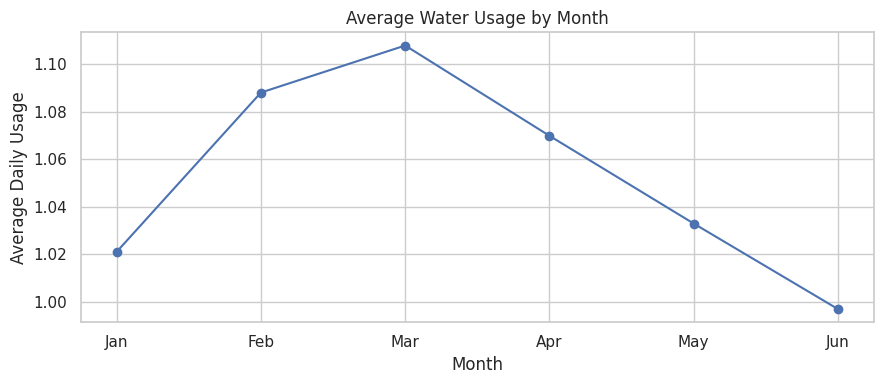

In [ ]:

# CELL 14: Monthly consumption trends

analysis_df["month_name"] = analysis_df["date"].dt.strftime("%b")

monthly_usage = (
    analysis_df.groupby("month_name")["usage"]
    .agg(["mean", "sum"])
    .reindex(["Jan", "Feb", "Mar", "Apr", "May", "Jun"])
)

display(monthly_usage.round(3))

monthly_usage["mean"].plot(
    kind="line",
    marker="o",
    figsize=(9, 4),
    title="Average Water Usage by Month"
)

plt.ylabel("Average Daily Usage")
plt.xlabel("Month")
plt.tight_layout()
plt.show()


In [ ]:

# CELL 15: Save final analysis files

analysis_df.to_csv("water_usage_analysis.csv", index=False)
spikes.to_csv("water_usage_spikes.csv", index=False)
locality_usage.to_csv("locality_usage_summary.csv")
type_summary.to_csv("connection_type_summary.csv")
repair_summary.to_csv("repair_analysis.csv")
monthly_usage.to_csv("monthly_usage_summary.csv")

print("All analysis files exported successfully.")


All analysis files exported successfully.


In [ ]:

from google.colab import files
files.download("water_usage_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MACHINE LEARNING


In [ ]:

# CELL 16: Prepare machine-learning features

from sklearn.ensemble import IsolationForest

ml_df = analysis_df.copy()

feature_columns = [
    "usage",
    "temperature",
    "rain",
    "previous_14day_median",
    "usage_ratio"
]

# Use available features and remove infinite values
X_numeric = ml_df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Impute missing values with each feature's median
X_numeric = X_numeric.fillna(X_numeric.median())

# Encode connection categories
X_categories = pd.get_dummies(
    ml_df[["type", "locality"]],
    dtype=int
)

X = pd.concat([X_numeric, X_categories], axis=1)

print("Rows for training:", X.shape[0])
print("Features for training:", X.shape[1])
print("Missing feature values:", X.isna().sum().sum())


Rows for training: 21600
Features for training: 13
Missing feature values: 0


In [ ]:

# CELL 17: Train anomaly detection model

model = IsolationForest(
    n_estimators=150,
    contamination=0.02,
    random_state=42
)

ml_df["anomaly_prediction"] = model.fit_predict(X)

# -1 means anomaly; 1 means normal
ml_df["is_anomaly"] = (
    ml_df["anomaly_prediction"] == -1
)

print("Model training completed.")
print("Total readings:", len(ml_df))
print("Flagged anomalies:", ml_df["is_anomaly"].sum())
print(
    "Anomaly percentage:",
    round(100 * ml_df["is_anomaly"].mean(), 2), "%"
)

display(
    ml_df.loc[
        ml_df["is_anomaly"],
        ["date", "connection_id", "locality",
         "type", "usage"]
    ].head(20)
)


Model training completed.
Total readings: 21600
Flagged anomalies: 432
Anomaly percentage: 2.0 %


,date,connection_id,locality,type,usage
49,2025-02-19,C0001,Hillview,Residential,1.548
180,2025-01-01,C0002,Central,Commercial,1.286
220,2025-02-10,C0002,Central,Commercial,1.091
226,2025-02-16,C0002,Central,Commercial,1.411
228,2025-02-18,C0002,Central,Commercial,5.846
229,2025-02-19,C0002,Central,Commercial,5.449
230,2025-02-20,C0002,Central,Commercial,5.922
265,2025-03-27,C0002,Central,Commercial,1.897
276,2025-04-07,C0002,Central,Commercial,1.532
309,2025-05-10,C0002,Central,Commercial,1.378


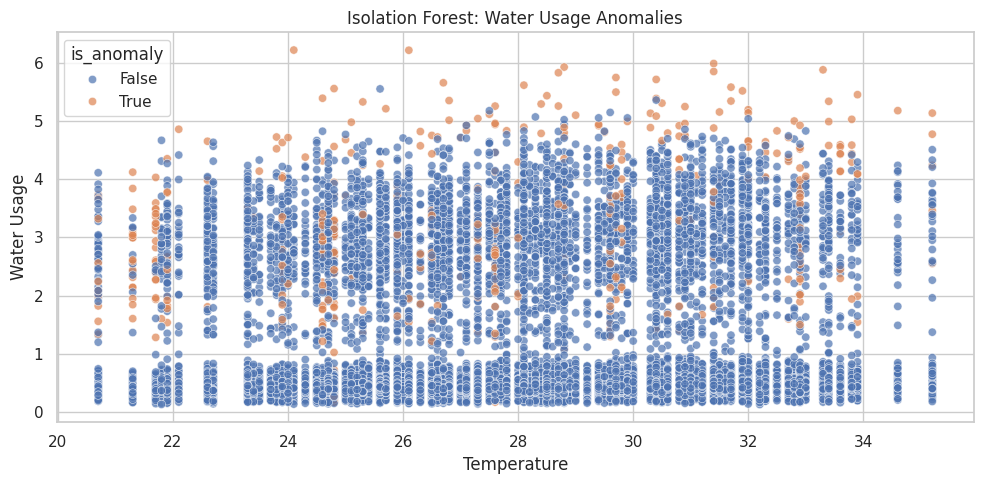

,count,mean,median,max
is_anomaly,,,,
False,21168,1.007121,0.513,5.548
True,432,3.285454,3.157,6.214


In [ ]:

# CELL 18: Visualize normal and anomalous readings

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=ml_df,
    x="temperature",
    y="usage",
    hue="is_anomaly",
    alpha=0.7
)

plt.title("Isolation Forest: Water Usage Anomalies")
plt.xlabel("Temperature")
plt.ylabel("Water Usage")
plt.tight_layout()
plt.show()

display(
    ml_df.groupby("is_anomaly")["usage"]
    .agg(["count", "mean", "median", "max"])
)


In [ ]:

# CELL 19: Export model outputs

ml_df.to_csv(
    "water_usage_ml_results.csv",
    index=False
)

ml_df.loc[ml_df["is_anomaly"]].to_csv(
    "water_usage_ml_anomalies.csv",
    index=False
)

print("Machine-learning results exported.")


Machine-learning results exported.


In [ ]:

from google.colab import files

files.download("water_usage_ml_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# CELL 20: Create the Excel analysis workbook

from google.colab import files

with pd.ExcelWriter(
    "Water_Usage_Insight_Analysis.xlsx",
    engine="openpyxl"
) as writer:

    # Main summary sheet
    summary = pd.DataFrame({
        "Metric": [
            "Total readings analyzed",
            "Flagged anomalies",
            "Anomaly percentage",
            "Locality with highest average usage",
            "Peak month by average usage",
            "Connections with lower usage after repair"
        ],
        "Result": [
            len(ml_df),
            int(ml_df["is_anomaly"].sum()),
            round(ml_df["is_anomaly"].mean() * 100, 2),
            locality_usage["mean"].idxmax(),
            monthly_usage["mean"].idxmax(),
            int((repair_summary["change_percent"] < 0).sum())
        ]
    })
    summary.to_excel(writer, sheet_name="Summary", index=False)

    # Analysis sheets
    locality_usage.to_excel(writer, sheet_name="Locality")
    weather_summary.to_excel(
        writer, sheet_name="Weather", index=False
    )
    type_summary.to_excel(writer, sheet_name="Connection_Type")
    spikes.to_excel(writer, sheet_name="Spike_Readings", index=False)
    repair_summary.to_excel(writer, sheet_name="Repair_Analysis")
    monthly_usage.to_excel(writer, sheet_name="Monthly_Demand")

    ml_df.loc[ml_df["is_anomaly"]].to_excel(
        writer, sheet_name="ML_Anomalies", index=False
    )

    ml_df.to_excel(
        writer, sheet_name="ML_All_Readings", index=False
    )

    # Format column widths and freeze headers
    for ws in writer.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        for column_cells in ws.columns:
            max_length = max(
                len(str(cell.value or ""))
                for cell in column_cells[:200]
            )
            ws.column_dimensions[
                column_cells[0].column_letter
            ].width = min(max_length + 2, 28)

print("Excel workbook created successfully!")
files.download("Water_Usage_Insight_Analysis.xlsx")


Excel workbook created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>